In [1]:
# Just Import the libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the cleaned dataset
df = pd.read_csv(r"Datasets\Transaction_risk_insights_cleaned.csv")
df["transaction_date"] = pd.to_datetime(df["transaction_date"],errors="coerce")
df["transaction_time"] = pd.to_datetime(df["transaction_time"],errors="coerce")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   transaction_id         550000 non-null  object        
 1   customer_id            550000 non-null  object        
 2   transaction_date       550000 non-null  datetime64[ns]
 3   transaction_time       550000 non-null  datetime64[ns]
 4   account_type           550000 non-null  object        
 5   transaction_type       550000 non-null  object        
 6   transaction_amount     550000 non-null  float64       
 7   transaction_direction  550000 non-null  object        
 8   account_balance        550000 non-null  float64       
 9   merchant_category      550000 non-null  object        
 10  state                  550000 non-null  object        
 11  credit_score           550000 non-null  int64         
 12  has_loan               550000 non-null  int6

In [4]:
df.sample(10)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
184648,TXN000184649,CUST071142,2020-09-05,1900-01-01 20:02:00,Current,Net_Banking,3110.36,Credit,21915.71,Healthcare,West Bengal,582,0,No Loan,0.0,Success,Mobile_App,Verified,0,20
518385,TXN000518386,CUST043404,2023-09-18,1900-01-01 10:38:00,Salary,IMPS,1322.06,Debit,19891.94,Education,Maharashtra,878,1,Business,4035.9,Success,Web,Verified,0,10
236995,TXN000236996,CUST052980,2021-02-26,1900-01-01 05:51:00,Fixed Deposit,ATM_Withdrawal,2000.00,Debit,12091.06,Fuel,West Bengal,425,1,Auto,1627.6,Success,ATM,Verified,0,5
336751,TXN000336752,CUST011622,2022-01-23,1900-01-01 23:21:00,Savings,ATM_Withdrawal,3000.00,Debit,10167.28,Government,West Bengal,847,0,No Loan,0.0,Success,Mobile_App,Pending,0,23
315719,TXN000315720,CUST020970,2021-11-14,1900-01-01 21:27:00,Savings,ATM_Withdrawal,5000.00,Debit,43137.43,Retail,Tamil Nadu,803,0,No Loan,0.0,Success,ATM,Verified,0,21
403537,TXN000403538,CUST005379,2022-09-02,1900-01-01 01:51:00,Savings,Auto_Debit,4358.93,Debit,104682.50,Salary,Tamil Nadu,589,0,No Loan,0.0,Reversed,Mobile_App,Verified,0,1
409754,TXN000409755,CUST020609,2022-09-22,1900-01-01 14:11:00,Current,NEFT,2950.93,Credit,40209.78,Retail,Maharashtra,614,0,No Loan,0.0,Success,POS_Terminal,Pending,0,14
323027,TXN000323028,CUST073172,2021-12-09,1900-01-01 15:35:00,Savings,NEFT,140318.08,Debit,118715.91,Insurance,Karnataka,391,0,No Loan,0.0,Success,API,Verified,0,15
386333,TXN000386334,CUST017028,2022-07-07,1900-01-01 02:22:00,Savings,NEFT,1782.58,Credit,67757.89,E-Commerce,Gujarat,678,0,No Loan,0.0,Success,API,Verified,0,2
439854,TXN000439855,CUST018843,2022-12-31,1900-01-01 11:46:00,Current,IMPS,463.71,Debit,24942.16,Healthcare,Telangana,428,0,No Loan,0.0,Success,Web,Verified,0,11


#### `1:-`Analyze is_fraud column distribution 

In [5]:

# we are just creating a summary for the is fraud column to see the distribution of fraud and non-fraud transactions
counts = df["is_fraud"].value_counts().sort_index()
percentages = df["is_fraud"].value_counts(normalize=True).sort_index() * 100

print("Non-Fraud transactions:", counts.loc[0])
print("Non-Fraud percentage:", round(percentages.loc[0], 2), "%")

print("Fraud transactions:", counts.loc[1])
print("Fraud percentage:", round(percentages.loc[1], 2), "%")

Non-Fraud transactions: 545127
Non-Fraud percentage: 99.11 %
Fraud transactions: 4873
Fraud percentage: 0.89 %



####  Observations
- **Total transactions:** in our data set is 550,000
- **Non-fraud transactions:** 545,127 (99.11%)
- **Fraud-labeled transactions:** 4,873 (0.89%)

#### `2:-`Now we will see which transaction type have the highest fraud rate

In [6]:
# Now we will going to compare transection types  to see which has the highest percentage of fraud labeled transections

fraud_by_type = df.groupby("transaction_type").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_type["Fraud_Rate_%"] = (
    fraud_by_type["Fraud_Transactions"] /
    fraud_by_type["Total_Transactions"] * 100
).round(2)

fraud_by_type = fraud_by_type.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_type)

                  Total_Transactions  Fraud_Transactions  Fraud_Rate_%
transaction_type                                                      
RTGS                           32964                 611          1.85
Cheque                         21711                 256          1.18
NEFT                           66615                 581          0.87
Credit_Card                    16426                 140          0.85
Net_Banking                    38458                 326          0.85
ATM_Withdrawal                 55106                 456          0.83
IMPS                           77038                 624          0.81
POS                            60278                 481          0.80
UPI                           153986                1211          0.79
Auto_Debit                     27418                 187          0.68


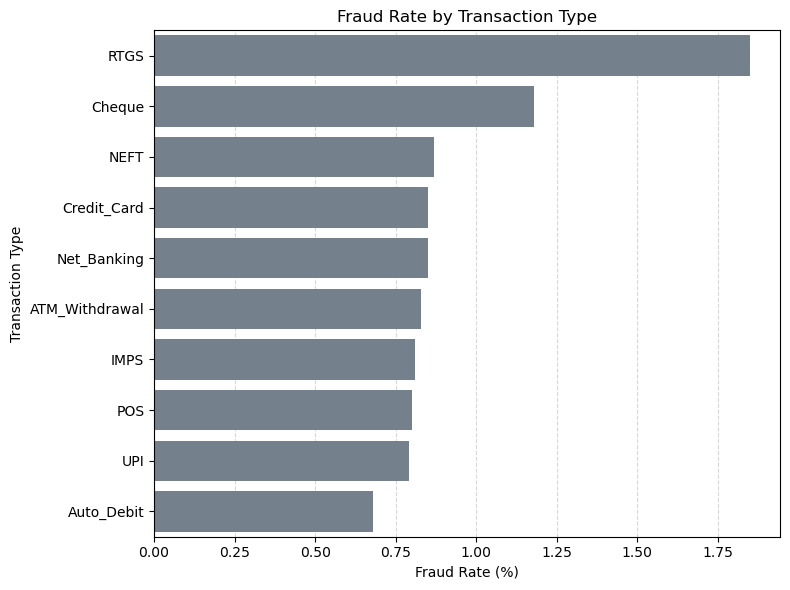

In [7]:
# Now we are just visualizing the fraud rate by transaction type using a bar plot
plt.figure(figsize=(8, 6))

sns.barplot(data=fraud_by_type.reset_index(),x="Fraud_Rate_%",y="transaction_type",color="slategray")

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Transaction Type")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()


#### Observations

- we found that the RTGS has the highest fraud rate which is  1.85%, followed by Cheque which has 1.18%.
- in our datat UPI has the highest number of fraud-labeled transactions, with 1,211 cases.
- Also the auto debit has the lowest fraud rate at 0.68%.


#### `3:-`Now we will do the Fraud Analysis by Transaction Hour


In [8]:
# Fraud analysis by hour will help us to find if there are specific hours of the day when fraud transactions happans more frequently.
fraud_by_hour = df.groupby("transaction_hour").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_hour["Fraud_Rate_%"] = (
    fraud_by_hour["Fraud_Transactions"] /
    fraud_by_hour["Total_Transactions"] * 100
).round(2)

print(fraud_by_hour)

                  Total_Transactions  Fraud_Transactions  Fraud_Rate_%
transaction_hour                                                      
0                              22928                 217          0.95
1                              23017                 182          0.79
2                              22740                 192          0.84
3                              22886                 211          0.92
4                              23082                 202          0.88
5                              22514                 193          0.86
6                              22931                 213          0.93
7                              22982                 218          0.95
8                              23242                 197          0.85
9                              22659                 202          0.89
10                             23111                 233          1.01
11                             23062                 196          0.85
12    

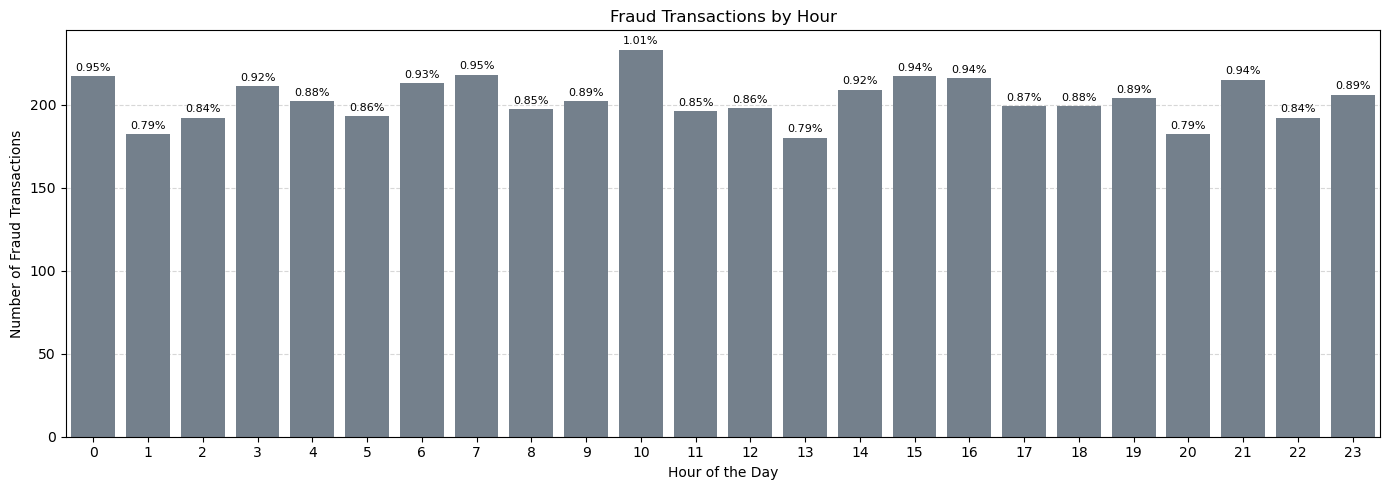

In [9]:
#now we are just visualizing the fraud rate by hour using a bar plot
plt.figure(figsize=(14,5))

ax = sns.barplot(data=fraud_by_hour.reset_index(),x="transaction_hour",y="Fraud_Transactions",color="slategray")

# just A=adding fraud rate percentage above each bar
for i, bar in enumerate(ax.patches):
    height = bar.get_height()
    hour = int(bar.get_x() + bar.get_width() / 2)

    fraud_rate = fraud_by_hour.loc[hour, "Fraud_Rate_%"]

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{fraud_rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.title("Fraud Transactions by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(range(0, 24))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Highest fraud rate:** found at 10 AM, with a fraud rate of 1.01% and 233 fraud-labeled transactions.
- **Lowest fraud rate:** found at 1 AM, 1 PM, and 8 PM, each with a fraud rate of 0.79%.
- and also Fraud rates remain relatively consistent throughout the day, ranging from 0.79% to 1.01%.

#### `4:-`Now we will do Fraud Analysis by Transaction Status

In [10]:
# This will help us find whether fraud-labeled transactions occur more frequently among successful, failed, reversed, or pending transactions.
fraud_by_status = df.groupby("transaction_status").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_status["Fraud_Rate_%"] = (
    fraud_by_status["Fraud_Transactions"]
    / fraud_by_status["Total_Transactions"] * 100
).round(2)

fraud_by_status = fraud_by_status.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_status)

                    Total_Transactions  Fraud_Transactions  Fraud_Rate_%
transaction_status                                                      
Pending                          10829                 103          0.95
Failed                           21905                 205          0.94
Reversed                         11019                 100          0.91
Success                         506247                4465          0.88


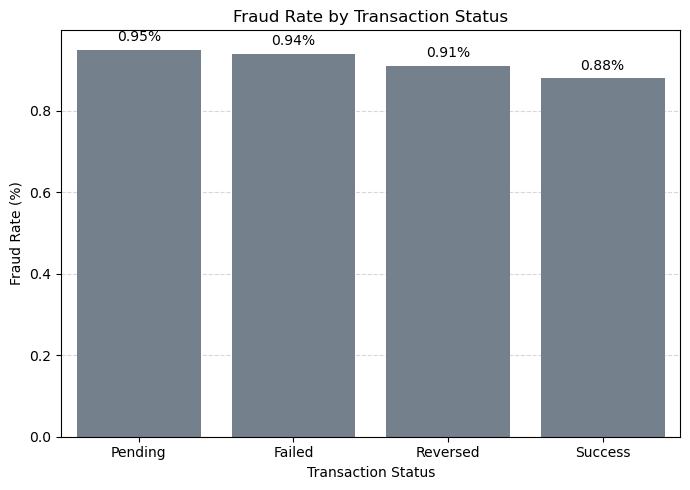

In [11]:
# Now we are just visualizing
plt.figure(figsize=(7, 5))

ax = sns.barplot(data=fraud_by_status.reset_index(),x="transaction_status",y="Fraud_Rate_%",color='slategray')

# just Add percentage labels above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Transaction Status")
plt.xlabel("Transaction Status")
plt.ylabel("Fraud Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observation
- **Highest fraud rate:** found in the  Pending transactions, with a fraud rate of 0.95% (103 fraud-labeled transactions).
- **Failed transactions:** Have a fraud rate of 0.94%, with 205 fraud-labeled transactions.
- **Reversed transactions:** Have a fraud rate of 0.91%, with 100 fraud-labeled transactions.
- **Successful transactions:** Have the lowest fraud rate at 0.88%,
- But the **Successful transactions** has the the highest number of fraud-labeled transactions which is ` 4,465`due to their large transaction volume.

#### `5:-`Now we will do the Fraud Analysis by Account Type

In [12]:
# It will help us to understand whether fraud rates differ between Savings, Current, Salary, NRI, and Fixed Deposit accounts.
fraud_by_account = df.groupby("account_type").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_account["Fraud_Rate_%"] = (
    fraud_by_account["Fraud_Transactions"]
    / fraud_by_account["Total_Transactions"] * 100
).round(2)

fraud_by_account = fraud_by_account.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_account)

               Total_Transactions  Fraud_Transactions  Fraud_Rate_%
account_type                                                       
Savings                    219651                2002          0.91
NRI                         43746                 390          0.89
Fixed Deposit               38888                 344          0.88
Current                    137648                1196          0.87
Salary                     110067                 941          0.85


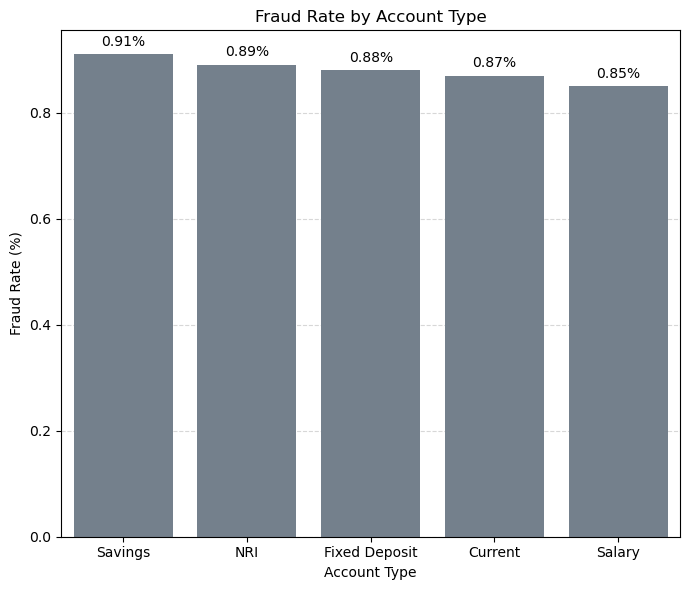

In [13]:
#Now we are just visualizing it
plt.figure(figsize=(7, 6))

ax = sns.barplot(data=fraud_by_account.reset_index(),x="account_type",y="Fraud_Rate_%",color='slategray')

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Fraud Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observation
- **Highest fraud rate:** found in thr  Savings accounts, with a fraud rate of 0.91% and 2,002 fraud-labeled transactions.
- **NRI accounts:** Have a fraud rate of 0.89%, with 390 fraud-labeled transactions.
- **Fixed Deposit accounts:** Have a fraud rate of 0.88%, with 344 fraud-labeled transactions.
- **Current accounts:** Have a fraud rate of 0.87%, with 1,196 fraud-labeled transactions.
- **Lowest fraud rate:** Salary accounts, at 0.85%, with 941 fraud-labeled transactions.

#### `6:-` Now we will do Fraud Analysis by Transaction Amount

In [14]:
# Now we will see the minimum,maximum and the average of the fraud amount
fraud_amount_summary = df.groupby("is_fraud")[
    "transaction_amount"
].agg(["count", "mean", "median", "min", "max"])

print(fraud_amount_summary)

           count           mean   median   min          max
is_fraud                                                   
0         545127   29106.685733  2030.99  2.40  10000000.00
1           4873  119446.211798  2691.95  8.65   6751663.36


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


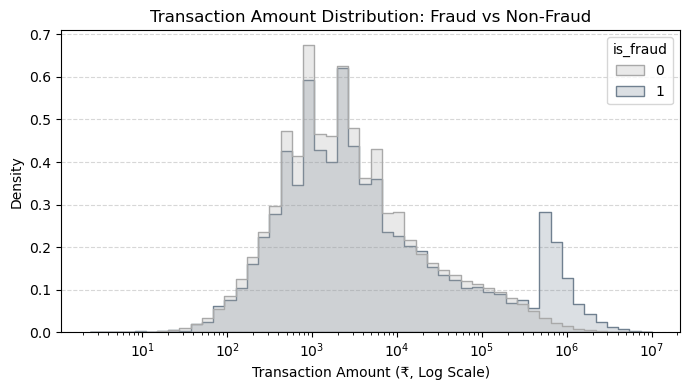

In [15]:
# now we are going to visualize it
plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x="transaction_amount",
    hue="is_fraud",
    bins=50,log_scale=True,element="step",stat="density",common_norm=False,palette=["darkgray", "slategray"]
)

plt.title("Transaction Amount Distribution: Fraud vs Non-Fraud")
plt.xlabel("Transaction Amount (₹, Log Scale)")
plt.ylabel("Density")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observation

- **Average transaction amount:** found in Fraud-labeled transactions have a higher average amount (1,19,446.21) than non-fraud transactions (29,106.69).
- **Median transaction amount:** found in Fraud-labeled transactions have a median amount of 2,691.95, compared with 2,030.99 for non-fraud transactions.
- **Minimum amount:** found in Fraud-labeled transactions start at 8.65, while non-fraud transactions start at 2.40.
- **Maximum amount:** The highest fraud-labeled transaction amount is 67,51,663.36, while the highest non-fraud transaction amount is 1,00,00,000.

#### `7:-`Now we will do Fraud Analysis by Transaction Direction.

In [16]:
# it will help us to find which direction has the highest fraud rate dabit or credit
fraud_by_direction = df.groupby("transaction_direction").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_direction["Fraud_Rate_%"] = (
    fraud_by_direction["Fraud_Transactions"]
    / fraud_by_direction["Total_Transactions"] * 100
).round(2)

fraud_by_direction = fraud_by_direction.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_direction)

                       Total_Transactions  Fraud_Transactions  Fraud_Rate_%
transaction_direction                                                      
Credit                             179606                1646          0.92
Debit                              370394                3227          0.87


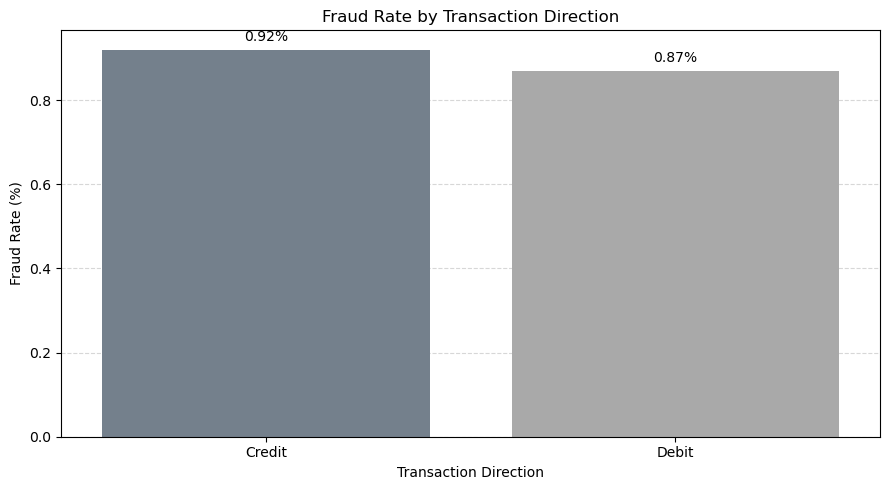

In [17]:
# now we will jsut vizulize it
# plt.figure(figsize=(8, 5))

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=fraud_by_direction.reset_index(),
    x="transaction_direction",
    y="Fraud_Rate_%",
    hue="transaction_direction",
    hue_order=["Credit", "Debit"],
    palette=["slategray", "darkgray"],
    legend=False
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Fraud Rate by Transaction Direction")
plt.xlabel("Transaction Direction")
plt.ylabel("Fraud Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### observation
- **Credit transactions:** Have a fraud rate of 0.92%, with 1,646 fraud-labeled transactions.
- **Debit transactions:** Have a fraud rate of 0.87%, with 3,227 fraud-labeled transactions.
- **Higher fraud rate:** Credit transactions have a slightly higher fraud rate than debit transactions.

#### `8:-`Now we will do fraud Analysis by Merchant Category.

In [18]:
# It will help us identify which merchant categories have higher fraud rates, such as Utilities, Food & Dining, and E-Commerce
fraud_by_merchant = df.groupby("merchant_category").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_merchant["Fraud_Rate_%"] = (
    fraud_by_merchant["Fraud_Transactions"]
    / fraud_by_merchant["Total_Transactions"] * 100
).round(2)

fraud_by_merchant = fraud_by_merchant.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_merchant)

                   Total_Transactions  Fraud_Transactions  Fraud_Rate_%
merchant_category                                                      
Peer Transfer                   38753                 362          0.93
E-Commerce                      54767                 502          0.92
Fuel                            21929                 201          0.92
Investment                      27380                 252          0.92
Entertainment                   32997                 300          0.91
Healthcare                      33015                 300          0.91
Retail                          66180                 594          0.90
Salary                          43937                 396          0.90
Travel                          44177                 388          0.88
Insurance                       22020                 191          0.87
Education                       27359                 236          0.86
Food & Dining                   54776                 471       

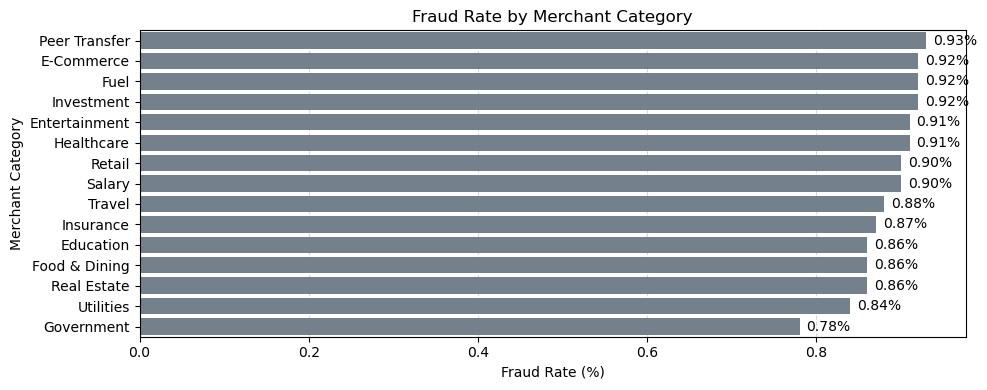

In [22]:
# just visualizing our findings using a bar plot
plt.figure(figsize=(10, 4))

ax = sns.barplot(
    data=fraud_by_merchant.reset_index(),
    x="Fraud_Rate_%",
    y="merchant_category",
    color="slategray"
)

for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Merchant Category")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Highest fraud rate:** found in Peer Transfer (person to person in our data), at 0.93%, with 362 fraud-labeled transactions.
- **E-Commerce, Fuel, and Investment:** Each has a fraud rate of around 0.92%.
- **Highest fraud count by volume:** found in Retail has the most fraud-labeled transactions, with 594 cases.
- **Lowest fraud rate:** found in Government transactions, at 0.78%, with 214 cases.
t.

#### `9:-` Now we do Fraud Analysis by Transaction Channel.

In [23]:
# Now we will  compare channels such as Mobile App, Web, ATM, and POS Terminal to see how fraud rates differ.
fraud_by_channel = df.groupby("channel").agg(
    Total_Transactions=("is_fraud", "count"),
    Fraud_Transactions=("is_fraud", "sum")
)

fraud_by_channel["Fraud_Rate_%"] = (
    fraud_by_channel["Fraud_Transactions"]
    / fraud_by_channel["Total_Transactions"] * 100
).round(2)

fraud_by_channel = fraud_by_channel.sort_values(
    "Fraud_Rate_%", ascending=False
)

print(fraud_by_channel)

              Total_Transactions  Fraud_Transactions  Fraud_Rate_%
channel                                                           
Branch                     54957                 520          0.95
POS_Terminal               60853                 557          0.92
API                        38635                 346          0.90
Web                       121010                1080          0.89
Mobile_App                208368                1809          0.87
ATM                        66177                 561          0.85


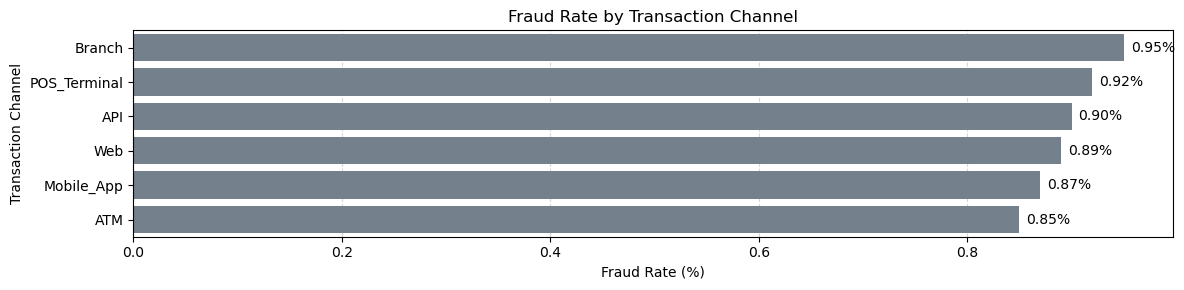

In [34]:
# Now we are just visualizing the fraud rate by transaction channel using a bar plot
plt.figure(figsize=(12, 3))

ax = sns.barplot(
    data=fraud_by_channel.reset_index(),
    x="Fraud_Rate_%",
    y="channel",
    color="slategray"
)

for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.title("Fraud Rate by Transaction Channel")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Transaction Channel")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observations
- **Highest fraud rate:** found in Branch transactions, at 0.95%, with 520 fraud-labeled transactions.
- **POS Terminal:** Has a fraud rate of 0.92%, with 557 fraud-labeled transactions.
- **Highest fraud count as per the volume:** found at Mobile App transactions have the most fraud-labeled transactions, with 1,809 cases.
- **Lowest fraud rate:** found at ATM transactions, at 0.85%, with 561 fraud-labeled transactions.